# чтоб ноутбук нормально запустился котики должны быть в корне и называться `0dc9ff026838851e803de7221dd33a6a.jpg` и `images.jpeg`

In [118]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Котик 1

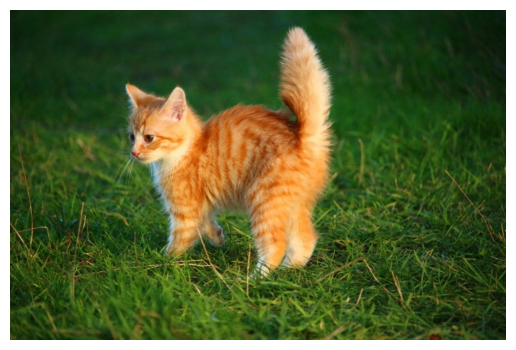

In [55]:
cat = cv2.cvtColor(
    cv2.imread("0dc9ff026838851e803de7221dd33a6a.jpg"),
    cv2.COLOR_BGR2RGB,
)

plt.axis("off")
plt.imshow(cat);

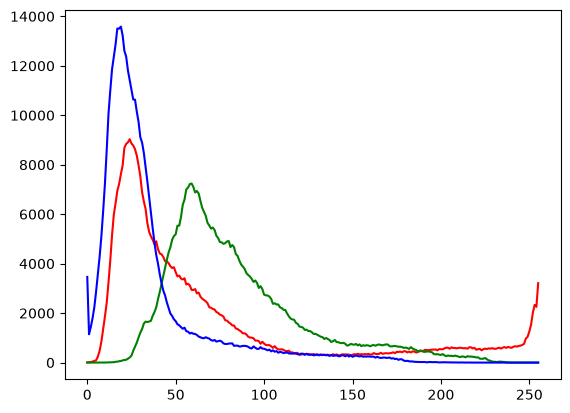

In [28]:
for i, c in zip(range(3), ['r', 'g', 'b']):
    hist = cv2.calcHist([cat],[i],None,[256],[0,256])
    plt.plot(hist, c=c)

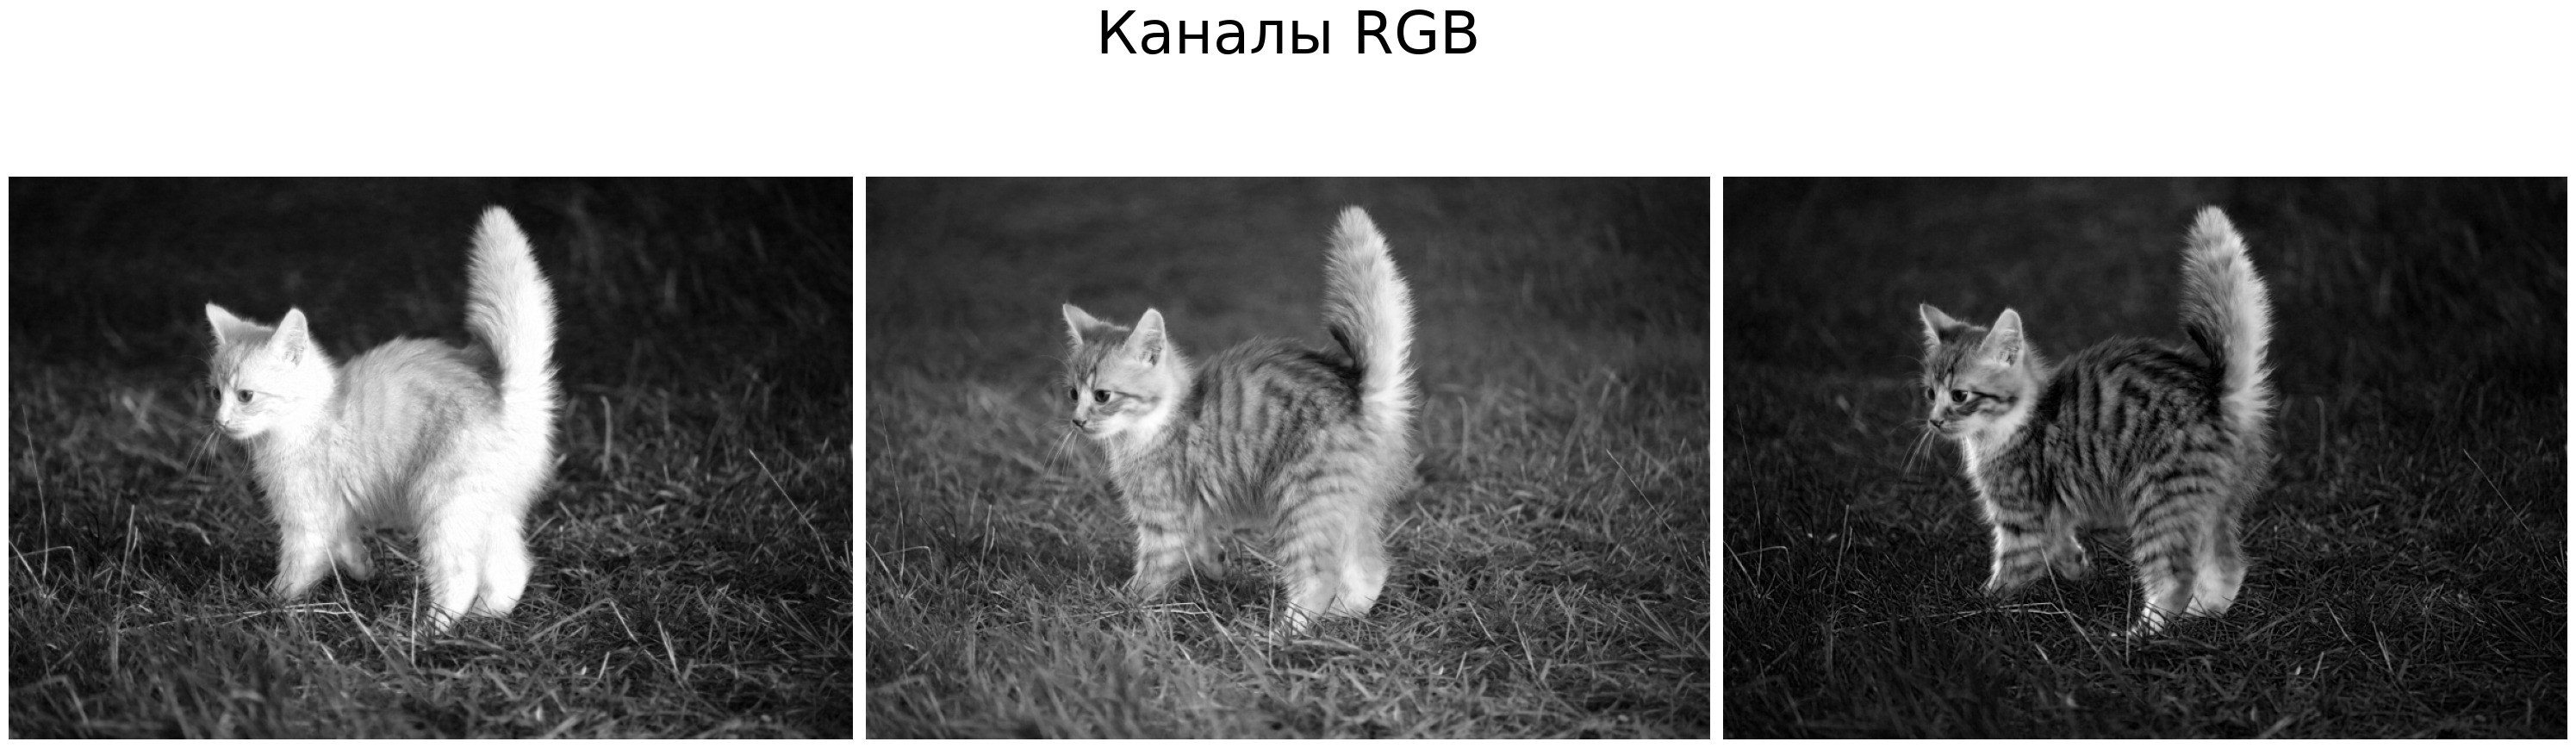

In [110]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10))
fig.suptitle("Каналы RGB", size=50)
for i, ax in zip(range(3), axes):
    ax.axis("off")
    ax.imshow(cat[:, :, i], cmap="grey")
plt.tight_layout()

Text(0.5, 1.0, 'Самое лучшее что смог из RGB получить')

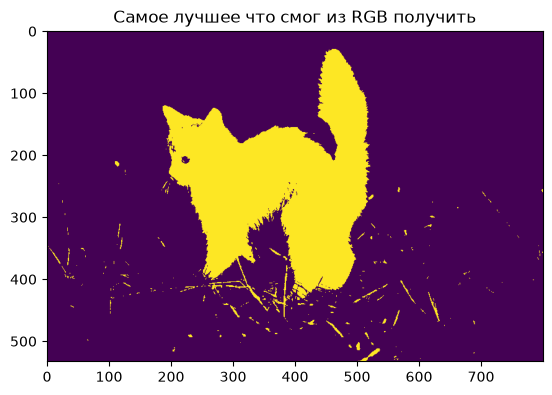

In [121]:
_, binary_rgb = cv2.threshold(cat[:, :, 0], 0, 255, cv2.THRESH_OTSU)
plt.imshow(binary_rgb)
plt.title("Самое лучшее что смог из RGB получить")

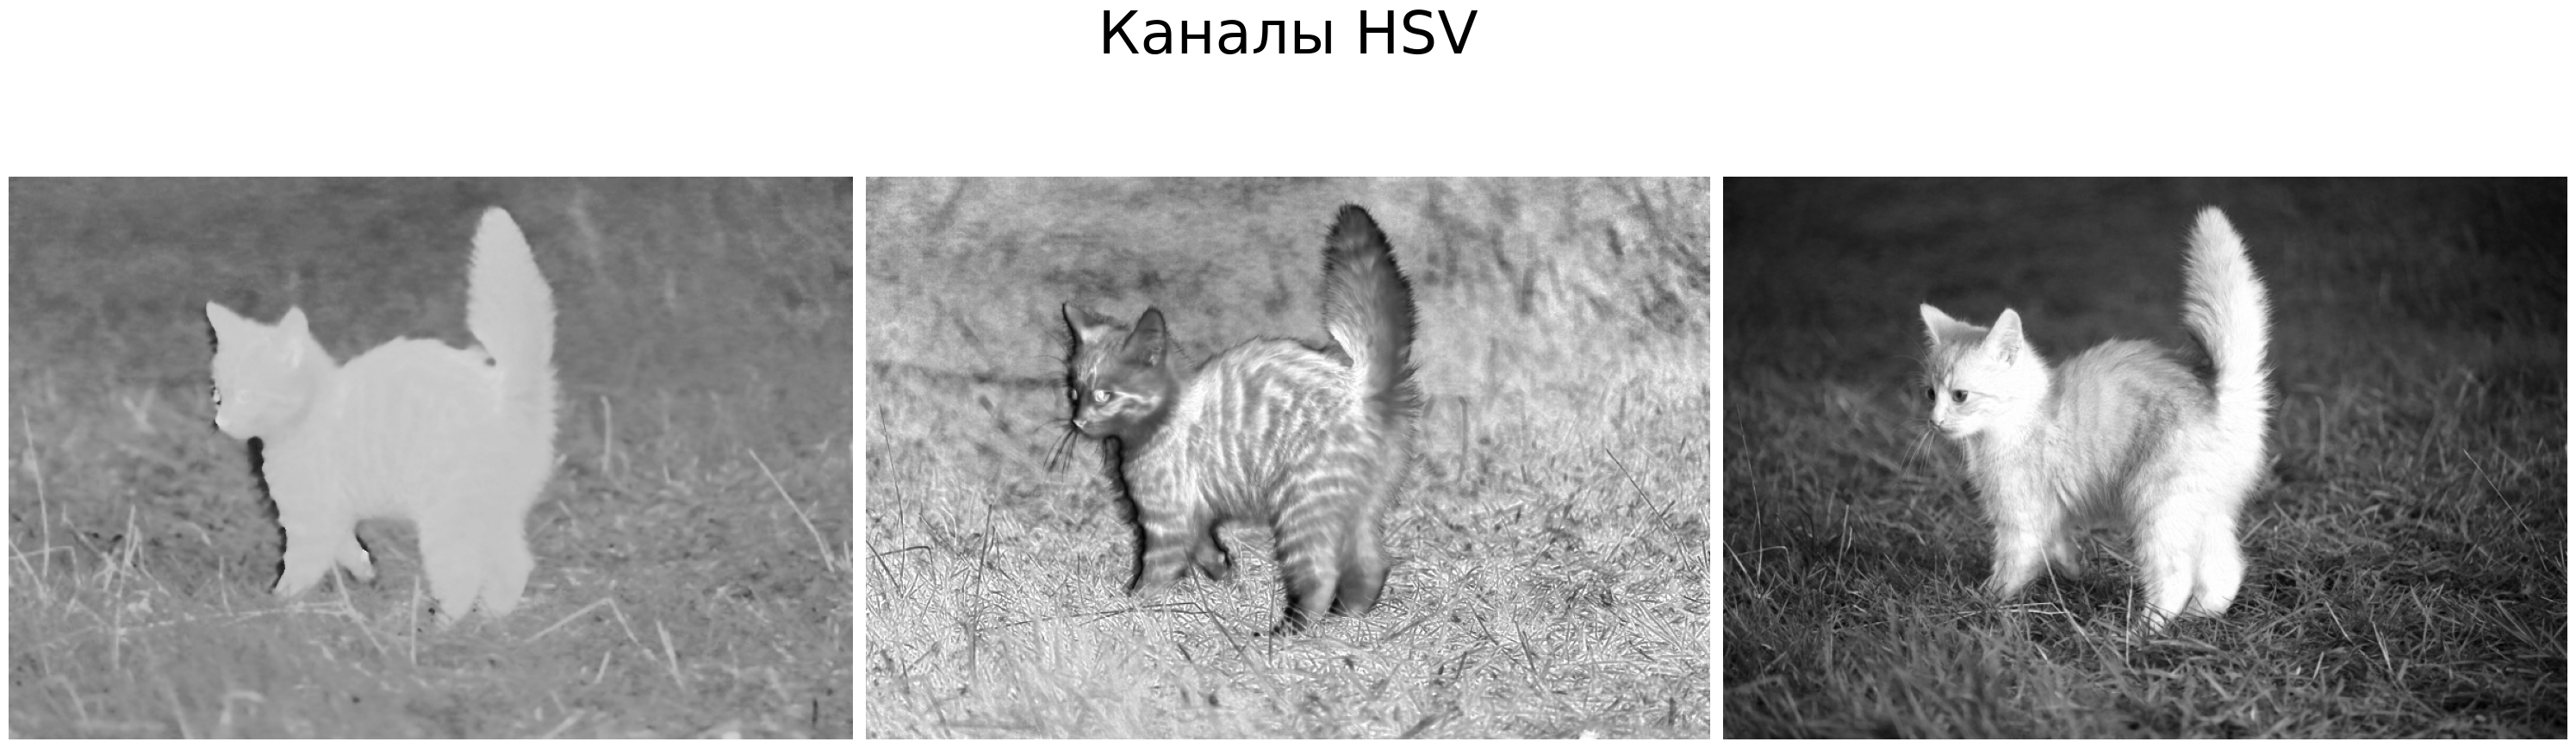

In [179]:
cat_hsv = cv2.cvtColor(
    cv2.imread("0dc9ff026838851e803de7221dd33a6a.jpg"),
    cv2.COLOR_RGB2HSV,
)

fig, axes = plt.subplots(1, 3, figsize=(30, 10))
fig.suptitle("Каналы HSV", size=50)
for i, ax in zip(range(3), axes):
    ax.axis("off")
    ax.imshow(cat_hsv[:, :, i], cmap="grey")
plt.tight_layout()

Text(0.5, 1.0, 'Самое лучшее что смог из HSV получить')

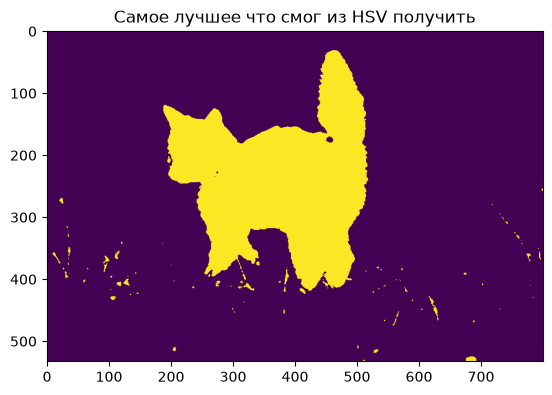

In [170]:
_, binary_hsv = cv2.threshold(cat_hsv[:, :, 0], 96, 255, cv2.THRESH_BINARY)
plt.imshow(binary_hsv)
plt.title("Самое лучшее что смог из HSV получить")

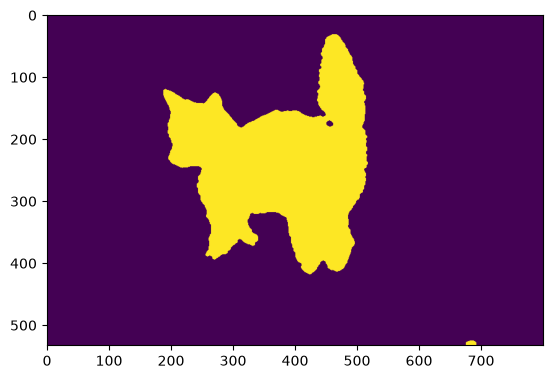

In [187]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

cat1_mask = cv2.morphologyEx(binary_hsv, cv2.MORPH_OPEN, kernel)
cat1_mask = cv2.morphologyEx(cat1_mask, cv2.MORPH_CLOSE, kernel) # там была маленькая точка внутри кота без этого
plt.imshow(cat1_mask)

# Котик 2

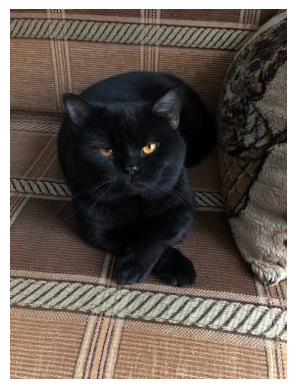

In [207]:
cat = cv2.cvtColor(
    cv2.imread("images.jpeg"),
    cv2.COLOR_BGR2RGB,
)

plt.axis("off")
plt.imshow(cat);

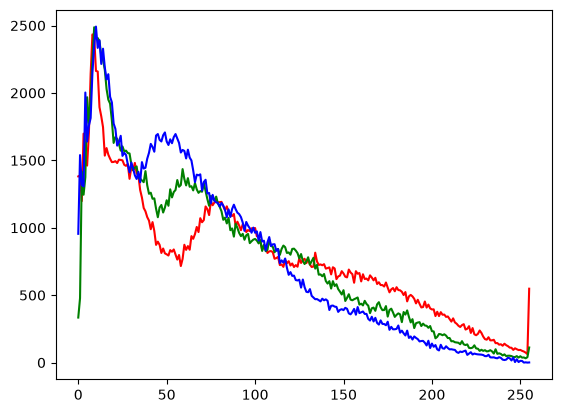

In [176]:
for i, c in zip(range(3), ['r', 'g', 'b']):
    hist = cv2.calcHist([cat],[i],None,[256],[0,256])
    plt.plot(hist, c=c)

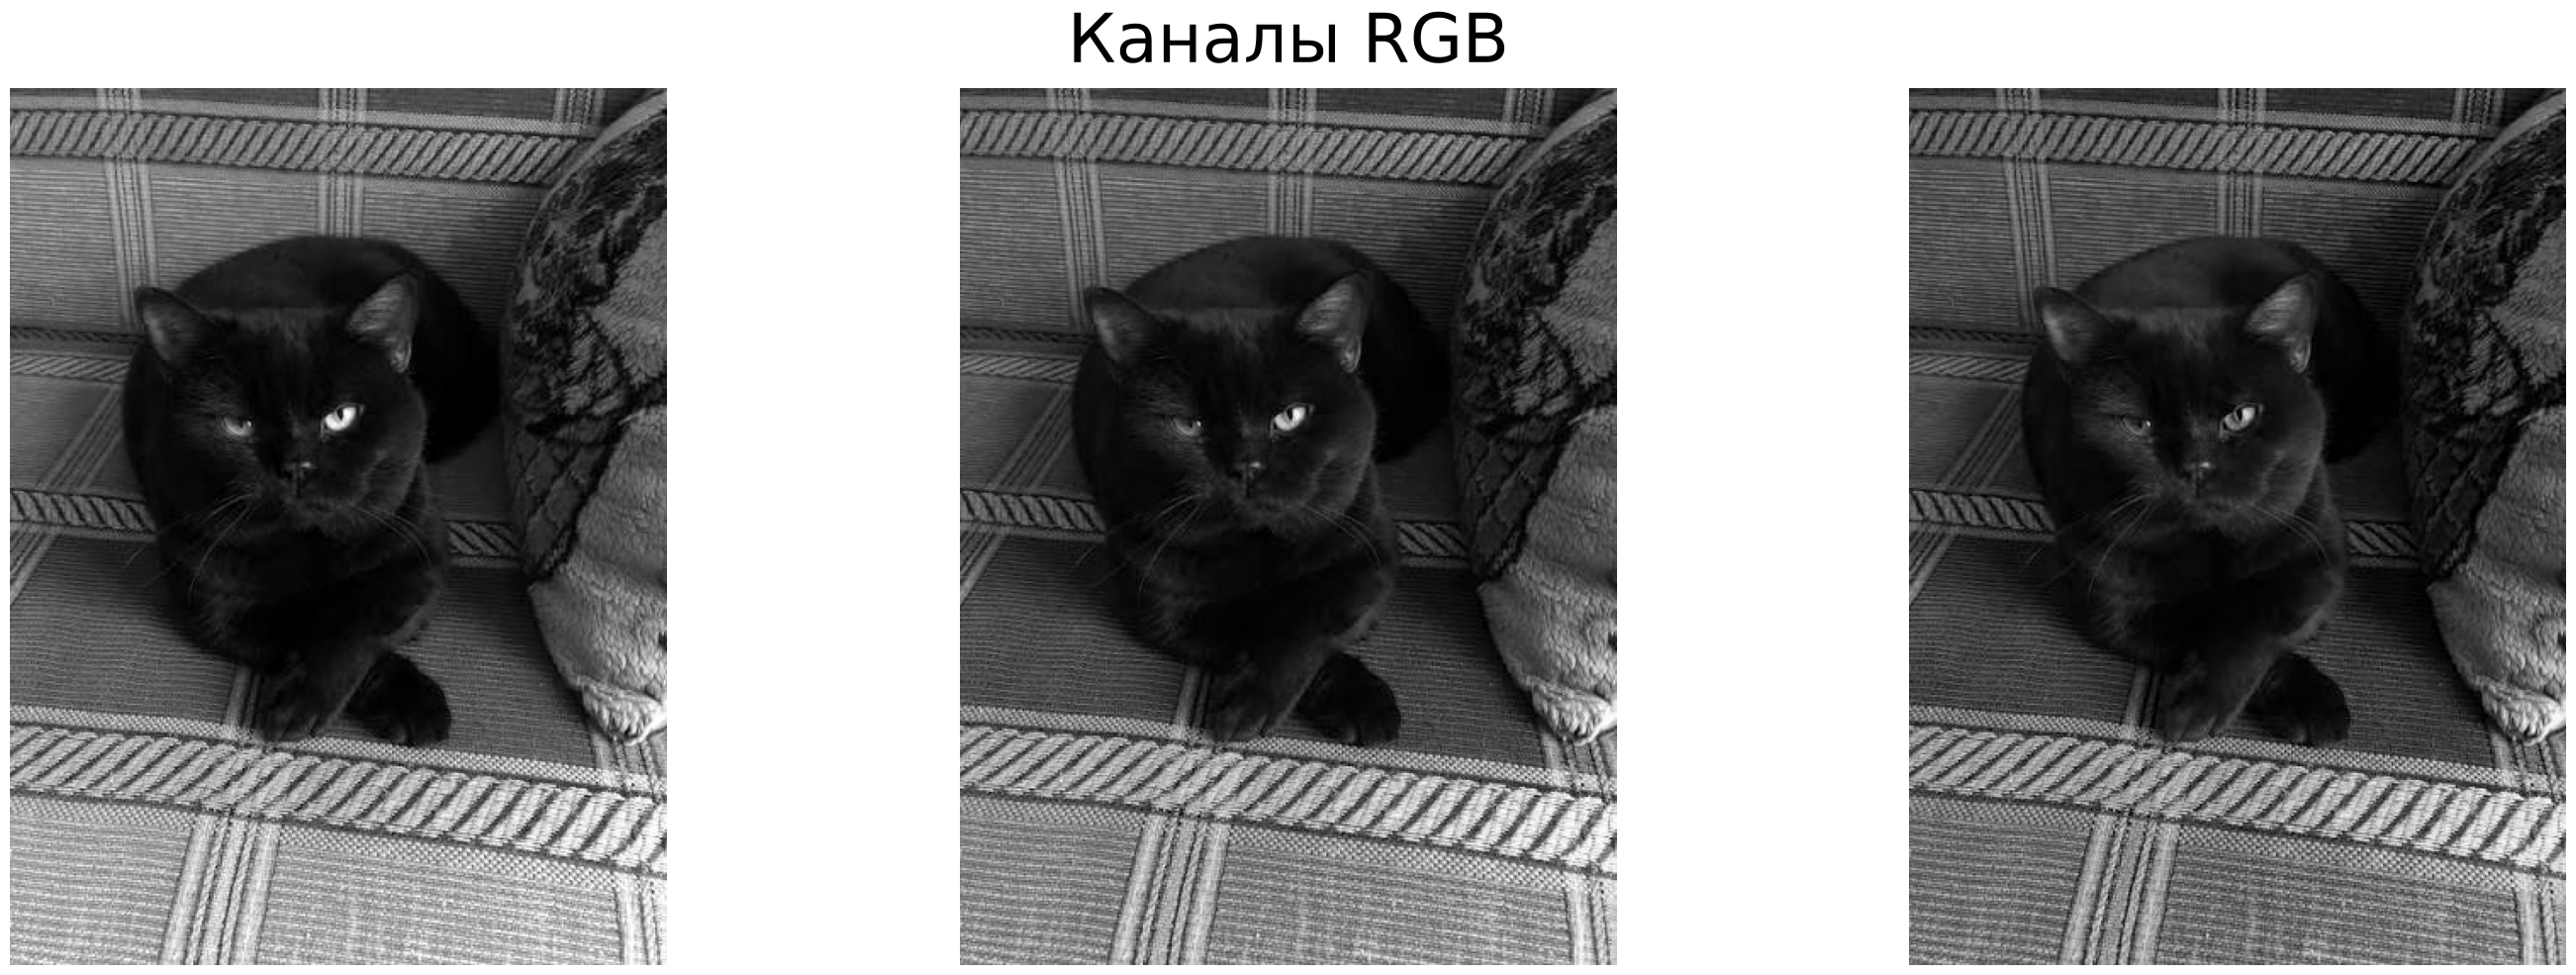

In [177]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10))
fig.suptitle("Каналы RGB", size=50)
for i, ax in zip(range(3), axes):
    ax.axis("off")
    ax.imshow(cat[:, :, i], cmap="grey")
plt.tight_layout()

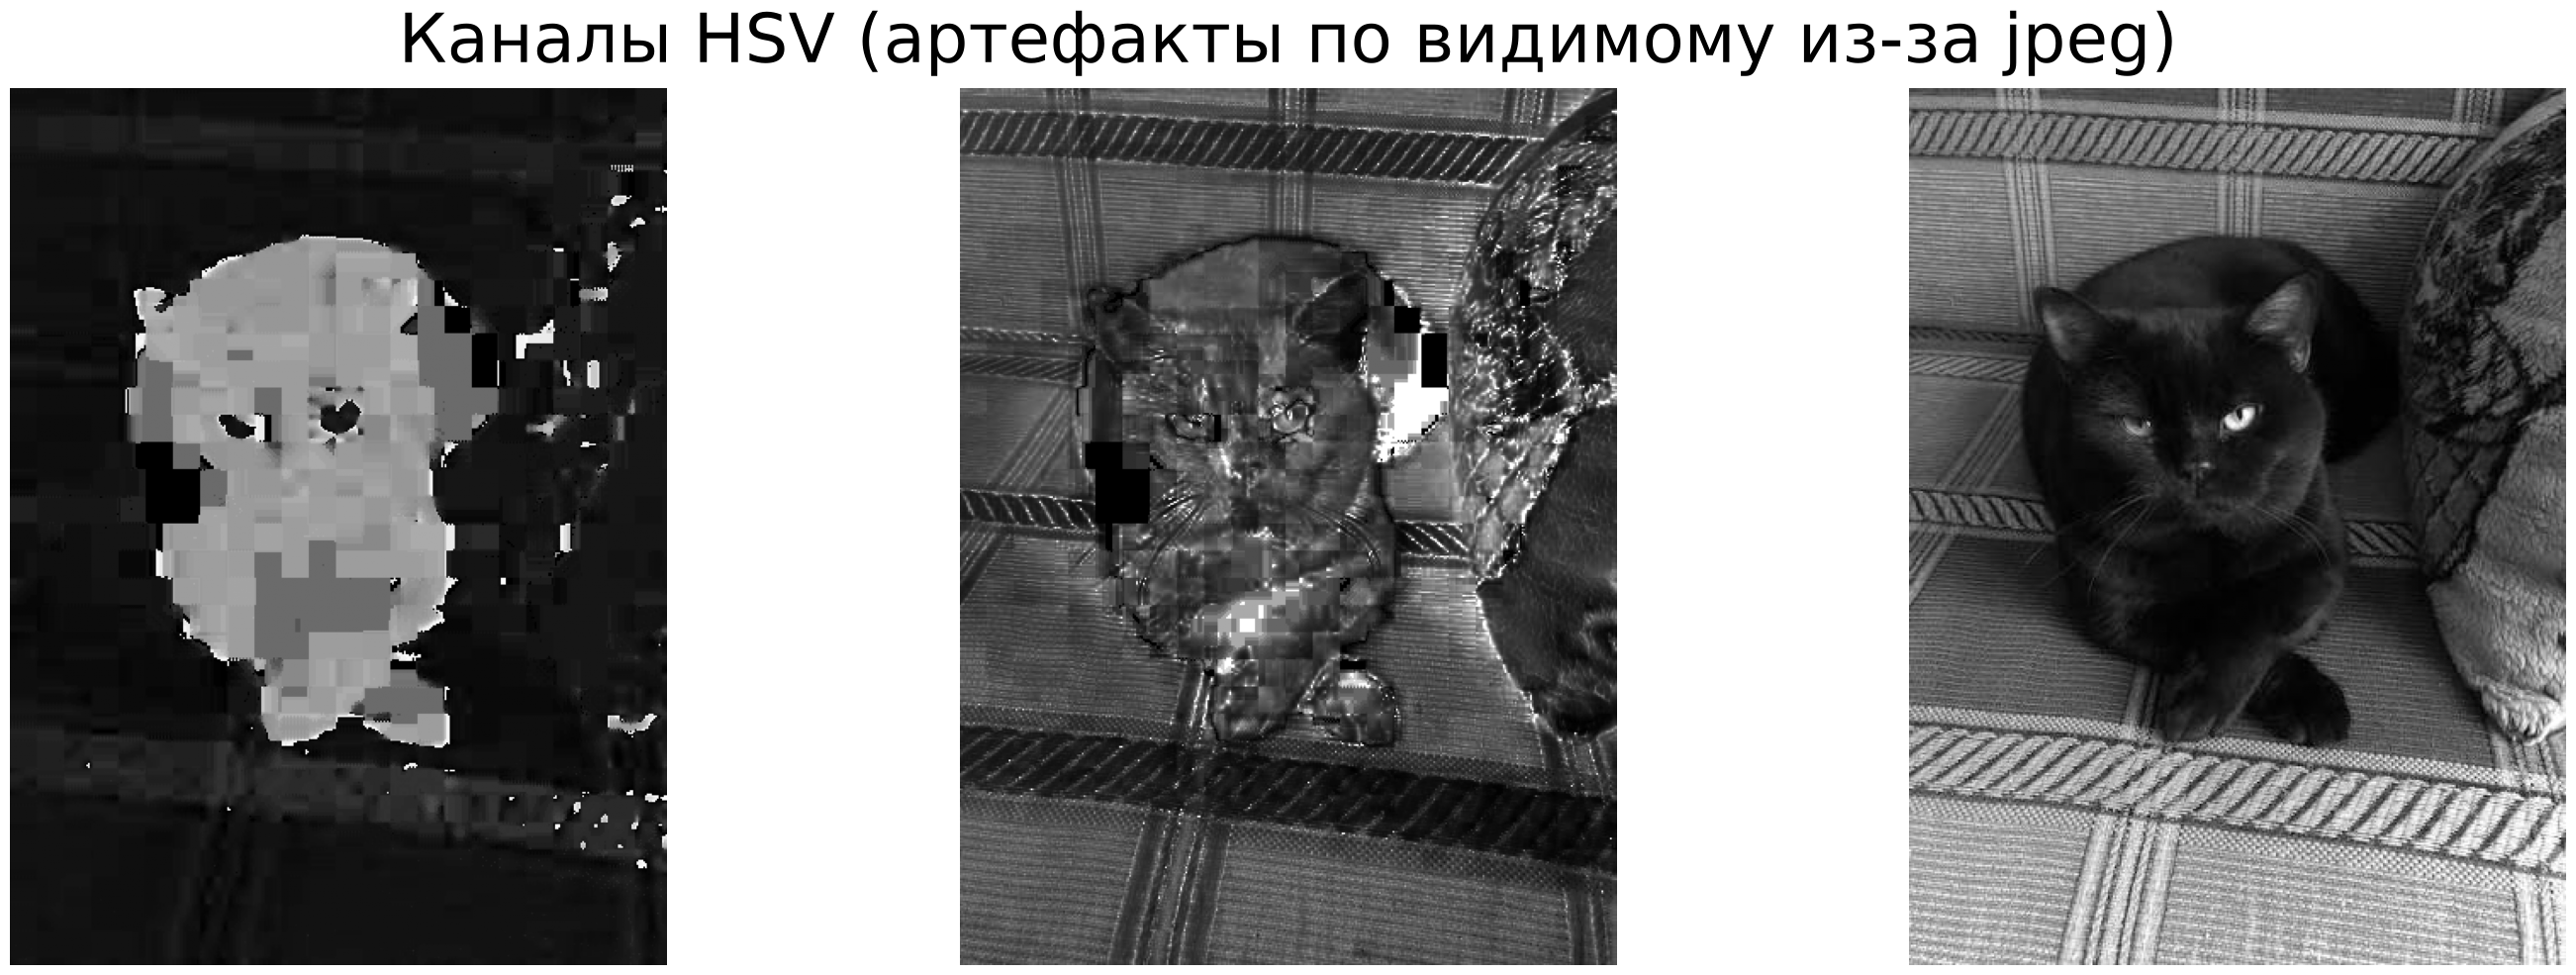

In [182]:
cat_hsv = cv2.cvtColor(
    cat,
    cv2.COLOR_RGB2HSV,
)

fig, axes = plt.subplots(1, 3, figsize=(30, 10))
fig.suptitle("Каналы HSV (артефакты по видимому из-за jpeg)", size=50)
for i, ax in zip(range(3), axes):
    ax.axis("off")
    ax.imshow(cat_hsv[:, :, i], cmap="grey")
plt.tight_layout()

Думаю дальше понятно, что лучше всего в grayscale работать или просто отобрать любой канал (по виду красный неплохо конрастирует с котом).

Еще как план попробовать h канал, но сегментация будет квадратной (можно попробовать улучшить ситуацию ядром размытия)

In [208]:
cat_try1 = cat[:, :, 0]
cat_try2 = cat_hsv[:, :, 0]

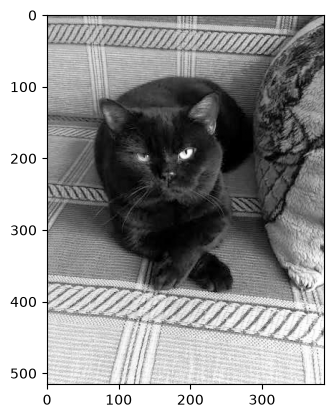

In [276]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(1, 1)) # честно не понял чем отличаются эти параметры
cat1_pp = clahe.apply(cat_try1)
plt.imshow(cat_clahe, cmap="grey")

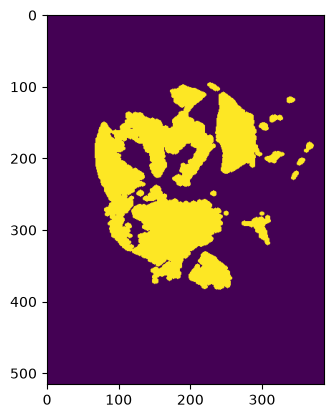

In [305]:
_, binary1 = cv2.threshold(cat1_pp, 50, 255, cv2.THRESH_BINARY_INV)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
binary1 = cv2.morphologyEx(binary1, cv2.MORPH_OPEN, kernel)

plt.imshow(binary1)

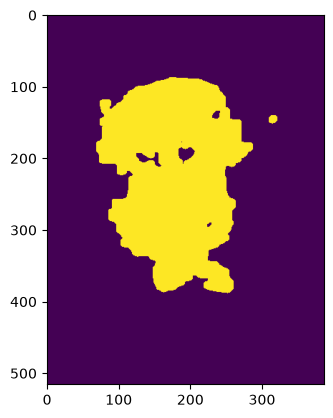

In [299]:
cat2_pp = cv2.GaussianBlur(cat_try2, (7, 7), 0)
_, binary2 = cv2.threshold(cat2_pp, 0, 255, cv2.THRESH_OTSU)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (10, 10))
binary2 = cv2.morphologyEx(binary2, cv2.MORPH_OPEN, kernel)

plt.imshow(binary2)

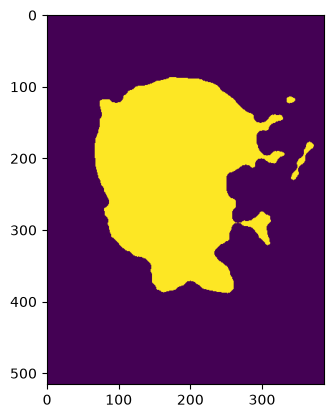

In [315]:
cat2_mask = binary1 | binary2
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))
cat2_mask = cv2.morphologyEx(cat2_mask, cv2.MORPH_CLOSE, kernel)

plt.imshow(cat2_mask)

# Посмотрим на маски и сравним с SOTA nn segmentation (SAM)

In [322]:
from sam_inference_vibecoded import segment_cat # это навайбкоженный скрипт инференса SAM на onnx

In [323]:
sam_cat1 = segment_cat("0dc9ff026838851e803de7221dd33a6a.jpg")
sam_cat2 = segment_cat("images.jpeg")

In [324]:
src_cat1 = cv2.cvtColor(cv2.imread("0dc9ff026838851e803de7221dd33a6a.jpg"), cv2.COLOR_BGR2RGB)
src_cat2 = cv2.cvtColor(cv2.imread("images.jpeg"), cv2.COLOR_BGR2RGB)

In [368]:
def summary(src, mask1, mask2, bg=np.array([0, 1, 0], dtype=float)):
    _, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(30, 10))
    src = src / 255.0
    mask1 = (mask1 / 255.0)[:, :, np.newaxis]
    mask2 = (mask2 / 255.0)[:, :, np.newaxis]
    ax1.imshow(src * mask1 + bg * (1 - mask1)); ax1.set_title("cv2", size=50)
    ax2.imshow(src * mask2 + bg * (1 - mask2)); ax2.set_title("sam", size=50)
    ax3.imshow(np.logical_xor(mask1, mask2), cmap="grey"); ax3.set_title("diff", size=50)

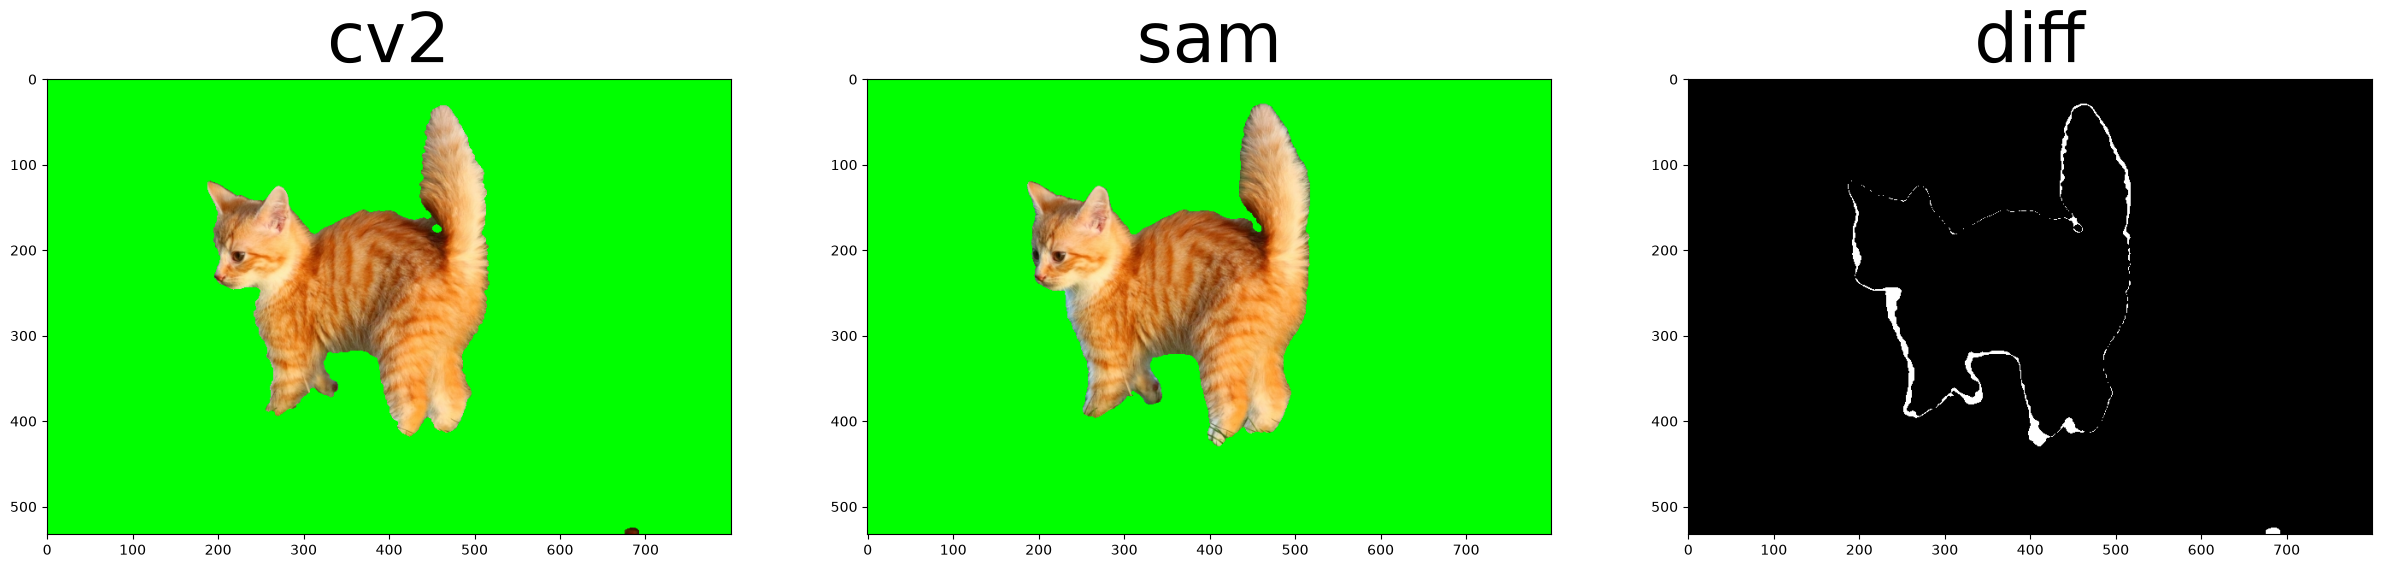

In [369]:
summary(src_cat1, cat1_mask, sam_cat1)

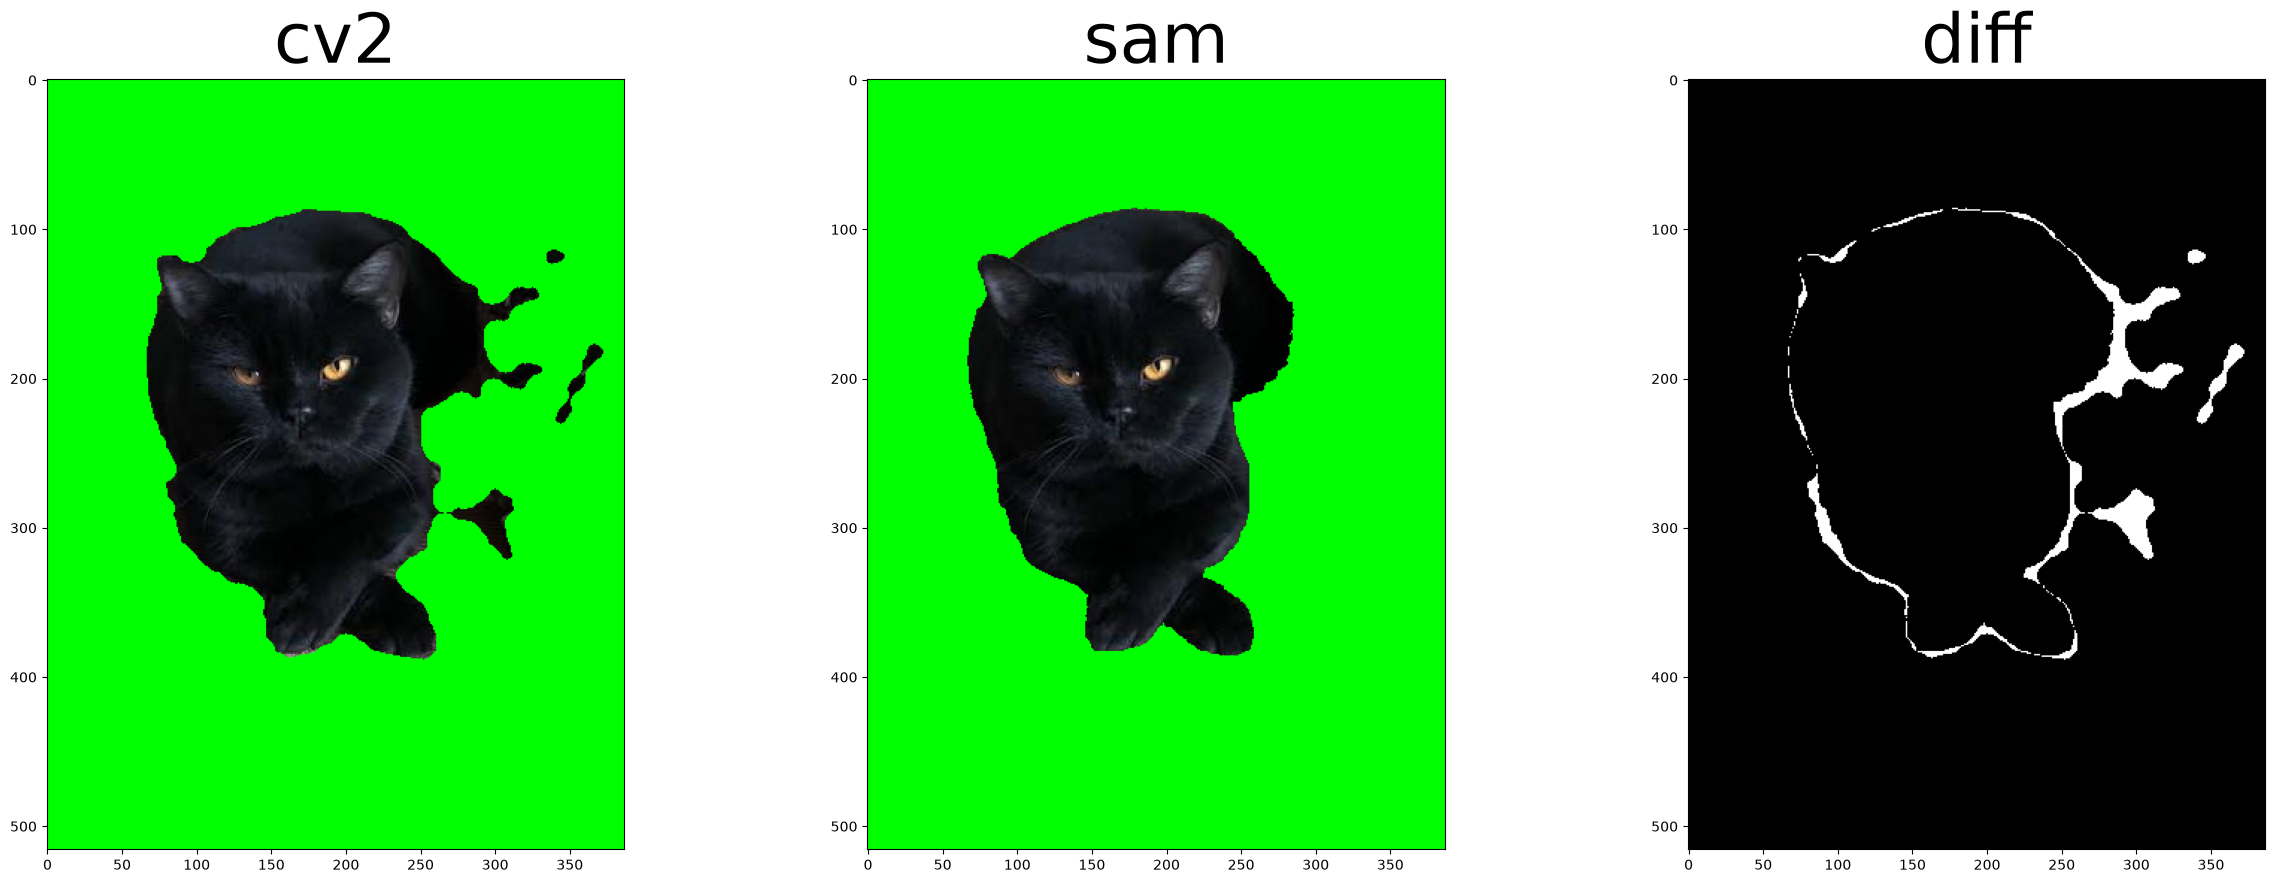

In [370]:
summary(src_cat2, cat2_mask, sam_cat2)